In [2]:
import os
os.environ["HF_HUB_OFFLINE"] = "1"             # never contact the Hugging Face Hub

import torch
from transformers import Sam3Model, Sam3Processor, BitsAndBytesConfig
from huggingface_hub.utils import GatedRepoError

# Load processor and model offline
processor = Sam3Processor.from_pretrained("models/sam3-4bit", local_files_only=True)
print(">>> Processor successfully loaded!")

model = Sam3Model.from_pretrained("models/sam3-4bit", device_map="auto", local_files_only=True)
print(">>> Model successfully loaded!")

>>> Processor successfully loaded!


Loading weights: 100%|██████████| 1468/1468 [00:01<00:00, 923.73it/s]


>>> Model successfully loaded!


file mode: I;16
presence score: 0.001
top 10 scores: [0.001 0.    0.    0.    0.    0.    0.    0.    0.    0.   ]
kept 1 instance(s)  (forced top-1, check it!)
best box (px): [83, 254, 2034, 4715]


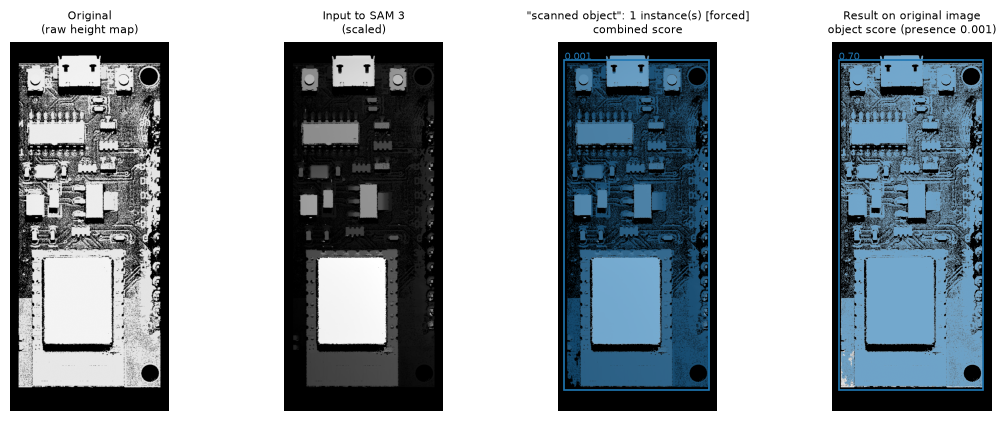

In [3]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/zil_00-10-83-13-99_261012_112259_Z.png"
text_prompt = "scanned object"
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.5                       # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 5) Visualize: original | SAM 3 input | result | result on original ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
z_disp   = z[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]               # raw heights, unscaled
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

# Blend all masks into one overlay layer
prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

# Object score = combined score / presence score  (e.g. 0.005 / 0.006 = 0.8)
if presence:                                   # not None and not 0
    object_scores = kept_scores / presence
else:
    object_scores = kept_scores                # no presence score: combined = object score

def draw_boxes(ax, label_scores, fmt=".2f"):
    """Draw boxes, score labels and the optional example box on one panel."""
    s = 1 / DISPLAY_DIV
    for i, (x1, y1, x2, y2) in enumerate(boxes_px):
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor=colors[i], linewidth=1.2))
        ax.text(x1 * s, y1 * s - 3, f"{float(label_scores[i]):{fmt}}", color=colors[i], fontsize=7)
    if example_box is not None:
        x1, y1, x2, y2 = example_box
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor="white", linestyle="--", linewidth=1.2))

# Figure size follows the image's width/height ratio
PANEL_H = 4.0                                      # inches per panel
GAP_IN  = 0.8                                      # space between panels, inches
panel_w = PANEL_H * w / h
fig, axes = plt.subplots(1, 4, figsize=(4 * panel_w + 3 * GAP_IN + 0.6, PANEL_H + 0.9),
                         layout="constrained")
fig.get_layout_engine().set(wspace=GAP_IN / panel_w)

raw_kw = dict(cmap="gray", vmin=0, vmax=float(z_disp.max()), aspect="equal")

# 1) Original raw height map
axes[0].imshow(z_disp, **raw_kw)
axes[0].set_title("Original\n(raw height map)", fontsize=8)

# 2) Input to SAM 3
axes[1].imshow(img_disp, aspect="equal")
axes[1].set_title("Input to SAM 3\n(scaled)", fontsize=8)

# 3) Result on the SAM 3 input, combined score (object x presence)
axes[2].imshow(img_disp, aspect="equal")
axes[2].imshow(overlay, aspect="equal")
draw_boxes(axes[2], kept_scores, fmt=".3f")
axes[2].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else "")
                  + "\ncombined score", fontsize=8)

# 4) Result on the original raw height map, object score (combined / presence)
axes[3].imshow(z_disp, **raw_kw)
axes[3].imshow(overlay, aspect="equal")
draw_boxes(axes[3], object_scores, fmt=".2f")
axes[3].set_title("Result on original image\n"
                  + (f"object score (presence {presence:.3f})" if presence else "object score"),
                  fontsize=8)

for ax in axes:
    ax.axis("off")
plt.show()

file mode: I;16
presence score: 0.938
top 10 scores: [0.761 0.746 0.734 0.733 0.73  0.716 0.712 0.707 0.706 0.695]
kept 27 instance(s)
best box (px): [212, 365, 461, 686]

27 box(es) in full-image pixels (sorted by score):
  #     x1     y1     x2     y2  width height  combined  object    mask px
  0    212    365    461    686    249    321     0.761    0.81      62672
  1   1405    362   1653    688    248    326     0.746    0.79      63712
  2    905   1649   1157   1791    252    142     0.734    0.78      26832
  3    513   2020    655   2279    142    259     0.733    0.78      31392
  4   1196   1354   1454   1490    258    136     0.730    0.78      28672
  5    338   1687    593   1888    255    201     0.716    0.76      42784
  6    630    200   1229    629    599    429     0.712    0.76     217520
  7    197   2080    441   2391    244    311     0.707    0.75      63408
  8    816   2513   1073   2656    257    143     0.706    0.75      27968
  9    214   1057   1019   

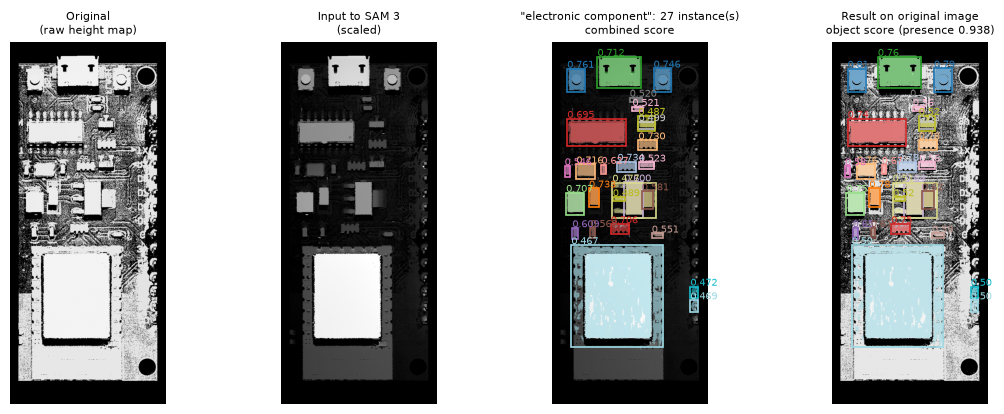

In [4]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/zil_00-10-83-13-99_261012_112259_Z.png"
text_prompt = "electronic component"    # "usb connector", "button"
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.46                      # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 4b) List all kept boxes in pixels ----------------
obj_scores = kept_scores / presence if presence else kept_scores     # combined / presence

print(f"\n{len(boxes_px)} box(es) in full-image pixels (sorted by score):")
print(f"{'#':>3} {'x1':>6} {'y1':>6} {'x2':>6} {'y2':>6} {'width':>6} {'height':>6} "
      f"{'combined':>9} {'object':>7} {'mask px':>10}")
box_list = []
for i, (x1, y1, x2, y2) in enumerate(boxes_px):
    x1, y1 = max(int(round(x1)), 0), max(int(round(y1)), 0)          # clamp to image
    x2, y2 = min(int(round(x2)), W), min(int(round(y2)), H)
    mask_px = int(masks[i].sum()) * DISPLAY_DIV ** 2                 # approx. full-res mask area
    box_list.append({"id": i, "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                     "width": x2 - x1, "height": y2 - y1,
                     "combined_score": round(float(kept_scores[i]), 4),
                     "object_score": round(float(obj_scores[i]), 4),
                     "mask_px": mask_px})
    print(f"{i:>3} {x1:>6} {y1:>6} {x2:>6} {y2:>6} {x2 - x1:>6} {y2 - y1:>6} "
          f"{float(kept_scores[i]):>9.3f} {float(obj_scores[i]):>7.2f} {mask_px:>10}")

# ---------------- 5) Visualize: original | SAM 3 input | result | result on original ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
z_disp   = z[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]               # raw heights, unscaled
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

# Blend all masks into one overlay layer
prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

# Object score = combined score / presence score  (e.g. 0.005 / 0.006 = 0.8)
if presence:                                   # not None and not 0
    object_scores = kept_scores / presence
else:
    object_scores = kept_scores                # no presence score: combined = object score

def draw_boxes(ax, label_scores, fmt=".2f"):
    """Draw boxes, score labels and the optional example box on one panel."""
    s = 1 / DISPLAY_DIV
    for i, (x1, y1, x2, y2) in enumerate(boxes_px):
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor=colors[i], linewidth=1.2))
        ax.text(x1 * s, y1 * s - 3, f"{float(label_scores[i]):{fmt}}", color=colors[i], fontsize=7)
    if example_box is not None:
        x1, y1, x2, y2 = example_box
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor="white", linestyle="--", linewidth=1.2))

# Figure size follows the image's width/height ratio
PANEL_H = 4.0                                      # inches per panel
GAP_IN  = 0.8                                      # space between panels, inches
panel_w = PANEL_H * w / h
fig, axes = plt.subplots(1, 4, figsize=(4 * panel_w + 3 * GAP_IN + 0.6, PANEL_H + 0.9),
                         layout="constrained")
fig.get_layout_engine().set(wspace=GAP_IN / panel_w)

raw_kw = dict(cmap="gray", vmin=0, vmax=float(z_disp.max()), aspect="equal")

# 1) Original raw height map
axes[0].imshow(z_disp, **raw_kw)
axes[0].set_title("Original\n(raw height map)", fontsize=8)

# 2) Input to SAM 3
axes[1].imshow(img_disp, aspect="equal")
axes[1].set_title("Input to SAM 3\n(scaled)", fontsize=8)

# 3) Result on the SAM 3 input, combined score (object x presence)
axes[2].imshow(img_disp, aspect="equal")
axes[2].imshow(overlay, aspect="equal")
draw_boxes(axes[2], kept_scores, fmt=".3f")
axes[2].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else "")
                  + "\ncombined score", fontsize=8)

# 4) Result on the original raw height map, object score (combined / presence)
axes[3].imshow(z_disp, **raw_kw)
axes[3].imshow(overlay, aspect="equal")
draw_boxes(axes[3], object_scores, fmt=".2f")
axes[3].set_title("Result on original image\n"
                  + (f"object score (presence {presence:.3f})" if presence else "object score"),
                  fontsize=8)

for ax in axes:
    ax.axis("off")
plt.show()

file mode: I;16
presence score: 0.19
top 10 scores: [0.158 0.075 0.058 0.044 0.037 0.036 0.036 0.031 0.029 0.027]
kept 1 instance(s)  (forced top-1, check it!)
best box (px): [636, 194, 1225, 624]

1 box(es) in full-image pixels (sorted by score):
  #     x1     y1     x2     y2  width height  combined  object    mask px
  0    636    194   1225    624    589    430     0.158    0.83     218176


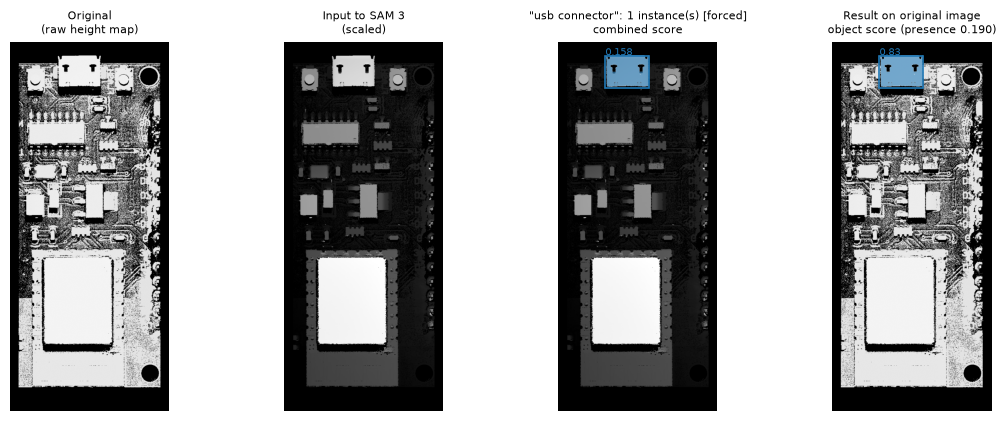

In [11]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/zil_00-10-83-13-99_261012_112259_Z.png"
text_prompt = "usb connector"
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.46                      # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 4b) List all kept boxes in pixels ----------------
obj_scores = kept_scores / presence if presence else kept_scores     # combined / presence

print(f"\n{len(boxes_px)} box(es) in full-image pixels (sorted by score):")
print(f"{'#':>3} {'x1':>6} {'y1':>6} {'x2':>6} {'y2':>6} {'width':>6} {'height':>6} "
      f"{'combined':>9} {'object':>7} {'mask px':>10}")
box_list = []
for i, (x1, y1, x2, y2) in enumerate(boxes_px):
    x1, y1 = max(int(round(x1)), 0), max(int(round(y1)), 0)          # clamp to image
    x2, y2 = min(int(round(x2)), W), min(int(round(y2)), H)
    mask_px = int(masks[i].sum()) * DISPLAY_DIV ** 2                 # approx. full-res mask area
    box_list.append({"id": i, "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                     "width": x2 - x1, "height": y2 - y1,
                     "combined_score": round(float(kept_scores[i]), 4),
                     "object_score": round(float(obj_scores[i]), 4),
                     "mask_px": mask_px})
    print(f"{i:>3} {x1:>6} {y1:>6} {x2:>6} {y2:>6} {x2 - x1:>6} {y2 - y1:>6} "
          f"{float(kept_scores[i]):>9.3f} {float(obj_scores[i]):>7.2f} {mask_px:>10}")

# ---------------- 5) Visualize: original | SAM 3 input | result | result on original ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
z_disp   = z[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]               # raw heights, unscaled
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

# Blend all masks into one overlay layer
prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

# Object score = combined score / presence score  (e.g. 0.005 / 0.006 = 0.8)
if presence:                                   # not None and not 0
    object_scores = kept_scores / presence
else:
    object_scores = kept_scores                # no presence score: combined = object score

def draw_boxes(ax, label_scores, fmt=".2f"):
    """Draw boxes, score labels and the optional example box on one panel."""
    s = 1 / DISPLAY_DIV
    for i, (x1, y1, x2, y2) in enumerate(boxes_px):
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor=colors[i], linewidth=1.2))
        ax.text(x1 * s, y1 * s - 3, f"{float(label_scores[i]):{fmt}}", color=colors[i], fontsize=7)
    if example_box is not None:
        x1, y1, x2, y2 = example_box
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor="white", linestyle="--", linewidth=1.2))

# Figure size follows the image's width/height ratio
PANEL_H = 4.0                                      # inches per panel
GAP_IN  = 0.8                                      # space between panels, inches
panel_w = PANEL_H * w / h
fig, axes = plt.subplots(1, 4, figsize=(4 * panel_w + 3 * GAP_IN + 0.6, PANEL_H + 0.9),
                         layout="constrained")
fig.get_layout_engine().set(wspace=GAP_IN / panel_w)

raw_kw = dict(cmap="gray", vmin=0, vmax=float(z_disp.max()), aspect="equal")

# 1) Original raw height map
axes[0].imshow(z_disp, **raw_kw)
axes[0].set_title("Original\n(raw height map)", fontsize=8)

# 2) Input to SAM 3
axes[1].imshow(img_disp, aspect="equal")
axes[1].set_title("Input to SAM 3\n(scaled)", fontsize=8)

# 3) Result on the SAM 3 input, combined score (object x presence)
axes[2].imshow(img_disp, aspect="equal")
axes[2].imshow(overlay, aspect="equal")
draw_boxes(axes[2], kept_scores, fmt=".3f")
axes[2].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else "")
                  + "\ncombined score", fontsize=8)

# 4) Result on the original raw height map, object score (combined / presence)
axes[3].imshow(z_disp, **raw_kw)
axes[3].imshow(overlay, aspect="equal")
draw_boxes(axes[3], object_scores, fmt=".2f")
axes[3].set_title("Result on original image\n"
                  + (f"object score (presence {presence:.3f})" if presence else "object score"),
                  fontsize=8)

for ax in axes:
    ax.axis("off")
plt.show()

file mode: I;16
presence score: 0.429
top 10 scores: [0.34  0.319 0.157 0.15  0.145 0.138 0.135 0.129 0.126 0.115]
kept 2 instance(s)
best box (px): [257, 460, 410, 595]

2 box(es) in full-image pixels (sorted by score):
  #     x1     y1     x2     y2  width height  combined  object    mask px
  0    257    460    410    595    153    135     0.340    0.79      14816
  1   1453    463   1601    596    148    133     0.319    0.74      14528


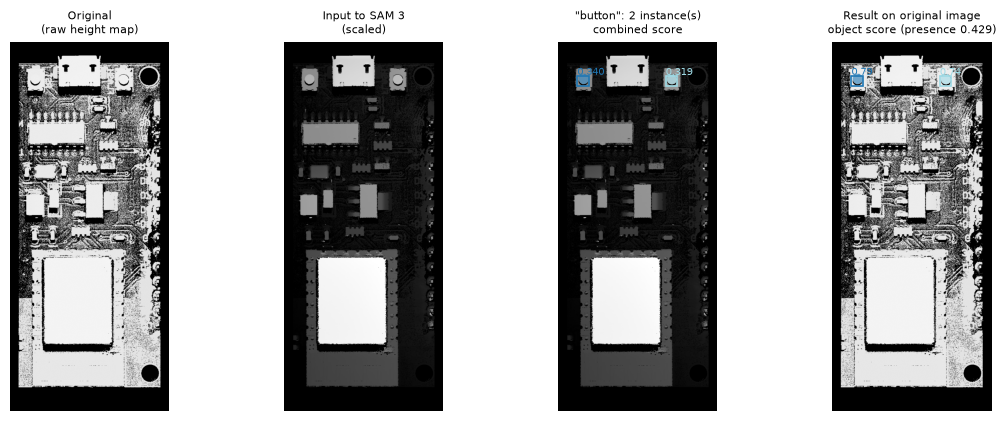

In [13]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/zil_00-10-83-13-99_261012_112259_Z.png"
text_prompt = "button"
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.3                       # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 4b) List all kept boxes in pixels ----------------
obj_scores = kept_scores / presence if presence else kept_scores     # combined / presence

print(f"\n{len(boxes_px)} box(es) in full-image pixels (sorted by score):")
print(f"{'#':>3} {'x1':>6} {'y1':>6} {'x2':>6} {'y2':>6} {'width':>6} {'height':>6} "
      f"{'combined':>9} {'object':>7} {'mask px':>10}")
box_list = []
for i, (x1, y1, x2, y2) in enumerate(boxes_px):
    x1, y1 = max(int(round(x1)), 0), max(int(round(y1)), 0)          # clamp to image
    x2, y2 = min(int(round(x2)), W), min(int(round(y2)), H)
    mask_px = int(masks[i].sum()) * DISPLAY_DIV ** 2                 # approx. full-res mask area
    box_list.append({"id": i, "x1": x1, "y1": y1, "x2": x2, "y2": y2,
                     "width": x2 - x1, "height": y2 - y1,
                     "combined_score": round(float(kept_scores[i]), 4),
                     "object_score": round(float(obj_scores[i]), 4),
                     "mask_px": mask_px})
    print(f"{i:>3} {x1:>6} {y1:>6} {x2:>6} {y2:>6} {x2 - x1:>6} {y2 - y1:>6} "
          f"{float(kept_scores[i]):>9.3f} {float(obj_scores[i]):>7.2f} {mask_px:>10}")

# ---------------- 5) Visualize: original | SAM 3 input | result | result on original ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
z_disp   = z[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]               # raw heights, unscaled
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

# Blend all masks into one overlay layer
prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

# Object score = combined score / presence score  (e.g. 0.005 / 0.006 = 0.8)
if presence:                                   # not None and not 0
    object_scores = kept_scores / presence
else:
    object_scores = kept_scores                # no presence score: combined = object score

def draw_boxes(ax, label_scores, fmt=".2f"):
    """Draw boxes, score labels and the optional example box on one panel."""
    s = 1 / DISPLAY_DIV
    for i, (x1, y1, x2, y2) in enumerate(boxes_px):
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor=colors[i], linewidth=1.2))
        ax.text(x1 * s, y1 * s - 3, f"{float(label_scores[i]):{fmt}}", color=colors[i], fontsize=7)
    if example_box is not None:
        x1, y1, x2, y2 = example_box
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor="white", linestyle="--", linewidth=1.2))

# Figure size follows the image's width/height ratio
PANEL_H = 4.0                                      # inches per panel
GAP_IN  = 0.8                                      # space between panels, inches
panel_w = PANEL_H * w / h
fig, axes = plt.subplots(1, 4, figsize=(4 * panel_w + 3 * GAP_IN + 0.6, PANEL_H + 0.9),
                         layout="constrained")
fig.get_layout_engine().set(wspace=GAP_IN / panel_w)

raw_kw = dict(cmap="gray", vmin=0, vmax=float(z_disp.max()), aspect="equal")

# 1) Original raw height map
axes[0].imshow(z_disp, **raw_kw)
axes[0].set_title("Original\n(raw height map)", fontsize=8)

# 2) Input to SAM 3
axes[1].imshow(img_disp, aspect="equal")
axes[1].set_title("Input to SAM 3\n(scaled)", fontsize=8)

# 3) Result on the SAM 3 input, combined score (object x presence)
axes[2].imshow(img_disp, aspect="equal")
axes[2].imshow(overlay, aspect="equal")
draw_boxes(axes[2], kept_scores, fmt=".3f")
axes[2].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else "")
                  + "\ncombined score", fontsize=8)

# 4) Result on the original raw height map, object score (combined / presence)
axes[3].imshow(z_disp, **raw_kw)
axes[3].imshow(overlay, aspect="equal")
draw_boxes(axes[3], object_scores, fmt=".2f")
axes[3].set_title("Result on original image\n"
                  + (f"object score (presence {presence:.3f})" if presence else "object score"),
                  fontsize=8)

for ax in axes:
    ax.axis("off")
plt.show()

file mode: I;16
presence score: 0.011
top 10 scores: [0.009 0.003 0.003 0.003 0.002 0.002 0.001 0.001 0.001 0.001]
kept 1 instance(s)  (forced top-1, check it!)
best box (px): [244, 1338, 2378, 3584]


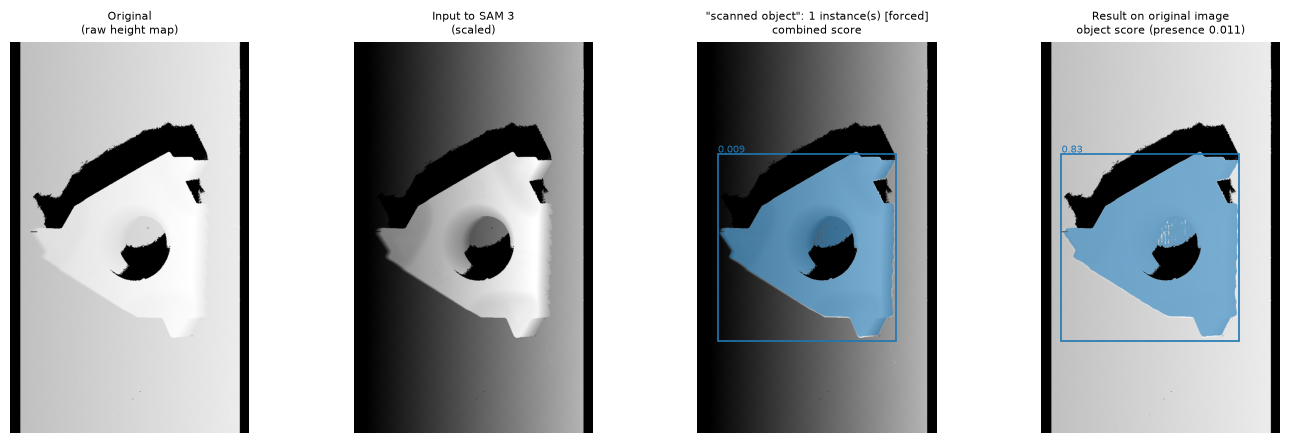

In [14]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/zil_00-01-14-66-99_261112_141735_Z_roll.png"
text_prompt = "scanned object"       
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.46                      # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 5) Visualize: original | SAM 3 input | result | result on original ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
z_disp   = z[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]               # raw heights, unscaled
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

# Blend all masks into one overlay layer
prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

# Object score = combined score / presence score  (e.g. 0.005 / 0.006 = 0.8)
if presence:                                   # not None and not 0
    object_scores = kept_scores / presence
else:
    object_scores = kept_scores                # no presence score: combined = object score

def draw_boxes(ax, label_scores, fmt=".2f"):
    """Draw boxes, score labels and the optional example box on one panel."""
    s = 1 / DISPLAY_DIV
    for i, (x1, y1, x2, y2) in enumerate(boxes_px):
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor=colors[i], linewidth=1.2))
        ax.text(x1 * s, y1 * s - 3, f"{float(label_scores[i]):{fmt}}", color=colors[i], fontsize=7)
    if example_box is not None:
        x1, y1, x2, y2 = example_box
        ax.add_patch(patches.Rectangle((x1 * s, y1 * s), (x2 - x1) * s, (y2 - y1) * s,
                                       fill=False, edgecolor="white", linestyle="--", linewidth=1.2))

# Figure size follows the image's width/height ratio
PANEL_H = 4.0                                      # inches per panel
GAP_IN  = 0.8                                      # space between panels, inches
panel_w = PANEL_H * w / h
fig, axes = plt.subplots(1, 4, figsize=(4 * panel_w + 3 * GAP_IN + 0.6, PANEL_H + 0.9),
                         layout="constrained")
fig.get_layout_engine().set(wspace=GAP_IN / panel_w)

raw_kw = dict(cmap="gray", vmin=0, vmax=float(z_disp.max()), aspect="equal")

# 1) Original raw height map
axes[0].imshow(z_disp, **raw_kw)
axes[0].set_title("Original\n(raw height map)", fontsize=8)

# 2) Input to SAM 3
axes[1].imshow(img_disp, aspect="equal")
axes[1].set_title("Input to SAM 3\n(scaled)", fontsize=8)

# 3) Result on the SAM 3 input, combined score (object x presence)
axes[2].imshow(img_disp, aspect="equal")
axes[2].imshow(overlay, aspect="equal")
draw_boxes(axes[2], kept_scores, fmt=".3f")
axes[2].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else "")
                  + "\ncombined score", fontsize=8)

# 4) Result on the original raw height map, object score (combined / presence)
axes[3].imshow(z_disp, **raw_kw)
axes[3].imshow(overlay, aspect="equal")
draw_boxes(axes[3], object_scores, fmt=".2f")
axes[3].set_title("Result on original image\n"
                  + (f"object score (presence {presence:.3f})" if presence else "object score"),
                  fontsize=8)

for ax in axes:
    ax.axis("off")
plt.show()

In [ ]:
"""
    The image uses the usual image-processing convention:

        (0,0) ────────────── x (columns) ──────────►  W
          │
          │        (x1, y1) = (244, 1338)
          │            ┌──────────────────────┐
          y            │                      │
        (rows)         │    scanned image     │
          │            │                      │
          │            └──────────────────────┘
          │                              (x2, y2) = (2378, 3584)
          ▼
          H

    - Origin (0, 0) is the top-left corner of the image.
    - x grows to the right: the column number, from 0 to W − 1.
    - y grows downward, not upward as in a math plot: the row number, from 0 to H − 1.
    - Units are pixels of the original full-size height map, not of the smaller display.

    The best box [244, 1338, 2378, 3584] is [x1, y1, x2, y2],
    So the box is 2,378 − 244 = 2,134 px wide and 3,584 − 1,338 = 2,246 px high.
"""

In [ ]:
"""
    Mapping between Height map and Sensor setting:

                Height map                                    Sensor setting
        Box width (x, along the laser line)	        ROI width (part of the laser's field of view)
        Box height (y, scan direction)	            Number of profiles to capture
        Height values inside the box (z)	        ROI height (measurement range)

    Define ROI and number of profiles to capture:

        ROI_width_threshold (ROI_WT)                    = 100
        number_of_profiles_to_capture_threshold (NoP_T) = 200
        ROI_height_threshold (ROI_HT)                   = 50


        optimized_ROI_width = [x1-ROI_WT, x2+ROI_WT]
        optimized_NoP_to_capture = y2 - y1 + NoP_T*2


            (0,0) ────────────── x (columns) ──────────►  W
              │
              │  (x1-ROI_WT, y1-NoP_T) = (144, 1138)
              │            ┌──────────────────────┐
              y            │                      │
            (rows)         │    optimized image   │
              │            │                      │
              │            └──────────────────────┘
              │                         (x2+ROI_WT, y2+NoP_T) = (2478, 3784)
              ▼
              H 

        
        Height values inside the box (z) = [smallest height value (background), largest height value] -> [min, max] (0-65535) to pixels?
        Then, optimized_ROI_height = [min_in_pixel-ROI_HT, max_in_pixel+ROI_HT]
"""

file mode: I;16
presence score: 0.011
top 10 scores: [0.009 0.003 0.003 0.003 0.002 0.002 0.001 0.001 0.001 0.001]
kept 1 instance(s)  (forced top-1, check it!)
best box (px): [244, 1338, 2378, 3584]

---- Detected box (full-image pixels) ----
x 243 .. 2379  (width 2136 px),  y 1338 .. 3585  (height 2247 px)
---- Height values inside the box (raw counts) ----
min 25452, max 33520   (absolute 25400 .. 33549)
object only: min 27259, max 33525
---- Optimized ROI ----
ROI width  : columns 143 .. 2479   -> 2336 px
profiles   : rows 1138 .. 3785      -> 2647 profiles
ROI height : raw 25402 .. 33570   -> range 8168 counts


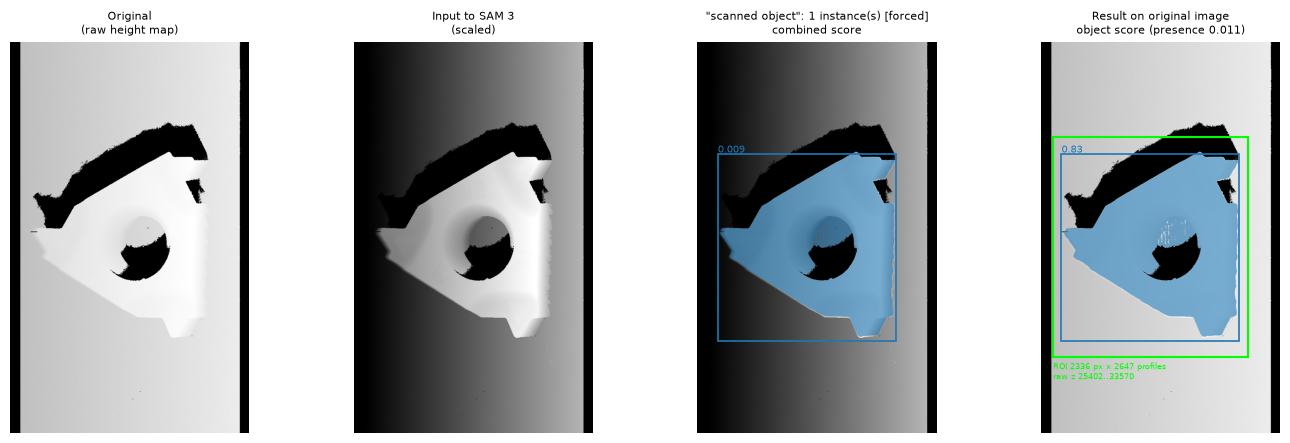

In [15]:
import torch, numpy as np, torch.nn.functional as Fnn
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image

# ---------------- Settings ----------------
image_path  = "images/zil_00-01-14-66-99_261112_141735_Z_roll.png"
text_prompt = "scanned object"
example_box = None                      # e.g. [x1, y1, x2, y2] in full-image pixels -> positive example
THR         = 0.46                      # score threshold
REL_THR     = None                      # e.g. 0.5 -> keep scores >= 0.5 * best score (overrides THR)
MIN_ONE     = True                      # if nothing passes, keep the single best candidate
DISPLAY_DIV = 4                         # 1 = full resolution masks; 4 = 1/4 size (faster, less RAM)
ALPHA       = 0.6

# ROI settings
ROI_WT      = 100                       # ROI width margin, px left/right (imager columns)
NoP_T       = 200                       # number-of-profiles margin, before/after (scan direction)
ROI_HT      = 50                        # ROI height margin, raw counts below/above
P_LO, P_HI  = 0.1, 99.9                 # robust min/max percentiles for raw heights (ignore spikes)

# ---------------- 1) Load height map and scale to 0..255 ----------------
raw = Image.open(image_path)
print("file mode:", raw.mode)           # I;16 = 16-bit heights, L = already 8-bit
z = np.array(raw).astype(np.float32)
if z.ndim == 3:                         # already RGB: use one channel
    z = z[..., 0]
valid = z > 0                           # 0 = no data (laser shadow)
lo, hi = np.percentile(z[valid], [1, 99.5])
g = np.clip((z - lo) / (hi - lo), 0, 1)
g[~valid] = 0
image = Image.fromarray((g * 255).astype(np.uint8)).convert("RGB")
W, H = image.size

# ---------------- 2) Run SAM 3 ----------------
proc_kwargs = dict(images=image, text=text_prompt, return_tensors="pt")
if example_box is not None:
    proc_kwargs.update(input_boxes=[[example_box]], input_boxes_labels=[[1]])
inputs = processor(**proc_kwargs).to(model.device)

with torch.inference_mode():
    outputs = model(**inputs)

# Scores = object score x presence score (same formula as the processor)
scores = outputs.pred_logits[0].float().sigmoid()
presence = None
if outputs.presence_logits is not None:
    presence = float(outputs.presence_logits[0].float().sigmoid())
    scores = scores * presence
scores = scores.cpu()

order = scores.argsort(descending=True)
print("presence score:", None if presence is None else round(presence, 3))
print("top 10 scores:", np.round(scores[order[:10]].numpy(), 3))

# ---------------- 3) Choose which instances to keep ----------------
if REL_THR is not None:
    keep = torch.nonzero(scores >= REL_THR * scores.max()).squeeze(1)
else:
    keep = torch.nonzero(scores > THR).squeeze(1)
forced = False
if keep.numel() == 0 and MIN_ONE:
    keep = order[:1]                    # fall back to the best candidate
    forced = True
keep = keep[scores[keep].argsort(descending=True)]   # highest score first
print(f"kept {len(keep)} instance(s)" + ("  (forced top-1, check it!)" if forced else ""))

# Copy what we need to the CPU, then free the GPU
mask_logits = outputs.pred_masks[0, keep].float().cpu()          # (K, h, w), low resolution
boxes_norm  = outputs.pred_boxes[0, keep].float().cpu()          # x1, y1, x2, y2, normalized 0..1
kept_scores = scores[keep]
best_box_px = (outputs.pred_boxes[0, order[0]].float().cpu() * torch.tensor([W, H, W, H])).tolist()
print("best box (px):", [round(v) for v in best_box_px])

del outputs, inputs
torch.cuda.empty_cache()

# ---------------- 4) Scale masks up on the CPU, one at a time ----------------
h, w = H // DISPLAY_DIV, W // DISPLAY_DIV
masks = np.zeros((len(keep), h, w), dtype=bool)
for i in range(len(keep)):
    m = Fnn.interpolate(mask_logits[i][None, None], size=(h, w), mode="bilinear", align_corners=False)
    masks[i] = (m[0, 0] > 0).numpy()                             # logit > 0 == probability > 0.5
masks &= valid[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]             # drop no-data pixels from masks
boxes_px = (boxes_norm * torch.tensor([W, H, W, H])).numpy()     # full-image pixels

# ---------------- 4b) Height range and optimized ROI ----------------
# Union of all kept boxes, in full-image pixels, clamped to the image
x1 = max(int(np.floor(boxes_px[:, 0].min())), 0)
y1 = max(int(np.floor(boxes_px[:, 1].min())), 0)
x2 = min(int(np.ceil(boxes_px[:, 2].max())), W)
y2 = min(int(np.ceil(boxes_px[:, 3].max())), H)

# Height values inside the box (raw 16-bit counts, valid pixels only)
#   min ~ background (smallest height), max ~ highest point of the object
z_box = z[y1:y2, x1:x2][valid[y1:y2, x1:x2]]
z_min, z_max = np.percentile(z_box, [P_LO, P_HI])                    # robust min / max
z_obj = z[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w][masks.any(axis=0)]   # object mask only (info)
z_obj_min, z_obj_max = (np.percentile(z_obj, [P_LO, P_HI]) if z_obj.size else (np.nan, np.nan))

# Optimized ROI
opt_x1 = max(x1 - ROI_WT, 0)                     # optimized_ROI_width = [x1 - ROI_WT, x2 + ROI_WT]
opt_x2 = min(x2 + ROI_WT, W)                     #   (clamped to the image width)
opt_width = opt_x2 - opt_x1
opt_y1 = y1 - NoP_T                              # first profile (may be < 0 = before this scan)
opt_y2 = y2 + NoP_T
opt_nop = (y2 - y1) + 2 * NoP_T                  # optimized_NoP_to_capture = y2 - y1 + 2 * NoP_T
opt_z_min = max(z_min - ROI_HT, 1)               # optimized_ROI_height = [min - ROI_HT, max + ROI_HT]
opt_z_max = min(z_max + ROI_HT, 65535)           #   (raw counts; 0 is reserved for no data)

print("\n---- Detected box (full-image pixels) ----")
print(f"x {x1} .. {x2}  (width {x2 - x1} px),  y {y1} .. {y2}  (height {y2 - y1} px)")
print("---- Height values inside the box (raw counts) ----")
print(f"min {z_min:.0f}, max {z_max:.0f}   (absolute {z_box.min():.0f} .. {z_box.max():.0f})")
print(f"object only: min {z_obj_min:.0f}, max {z_obj_max:.0f}")
print("---- Optimized ROI ----")
print(f"ROI width  : columns {opt_x1} .. {opt_x2}   -> {opt_width} px")
print(f"profiles   : rows {opt_y1} .. {opt_y2}      -> {opt_nop} profiles")
print(f"ROI height : raw {opt_z_min:.0f} .. {opt_z_max:.0f}   -> range {opt_z_max - opt_z_min:.0f} counts")

roi = {"x_start": opt_x1, "x_end": opt_x2, "width": opt_width,
       "profile_start": opt_y1, "profile_end": opt_y2, "number_of_profiles": opt_nop,
       "z_min_raw": float(opt_z_min), "z_max_raw": float(opt_z_max),
       "box_z_min_raw": float(z_min), "box_z_max_raw": float(z_max)}

# ---------------- 5) Visualize: original | SAM 3 input | result | result on original ----------------
img_disp = np.asarray(image)[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]
z_disp   = z[::DISPLAY_DIV, ::DISPLAY_DIV][:h, :w]               # raw heights, unscaled
N = len(masks)
colors = plt.get_cmap("tab20")(np.linspace(0, 1, max(N, 1)))[:, :3].astype(np.float32)

# Blend all masks into one overlay layer
prem = np.zeros((h, w, 3), np.float32)
acc  = np.zeros((h, w), np.float32)
for i in range(N):
    m = masks[i]
    if m.any():
        prem[m] = ALPHA * colors[i] + (1 - ALPHA) * prem[m]
        acc[m]  = ALPHA + (1 - ALPHA) * acc[m]
overlay = np.zeros((h, w, 4), np.float32)
cov = acc > 0
overlay[cov, :3] = prem[cov] / acc[cov, None]
overlay[..., 3] = acc

# Object score = combined score / presence score  (e.g. 0.005 / 0.006 = 0.8)
if presence:                                   # not None and not 0
    object_scores = kept_scores / presence
else:
    object_scores = kept_scores                # no presence score: combined = object score

s = 1 / DISPLAY_DIV                            # full-image pixels -> display pixels

def draw_boxes(ax, label_scores, fmt=".2f"):
    """Draw boxes, score labels and the optional example box on one panel."""
    for i, (bx1, by1, bx2, by2) in enumerate(boxes_px):
        ax.add_patch(patches.Rectangle((bx1 * s, by1 * s), (bx2 - bx1) * s, (by2 - by1) * s,
                                       fill=False, edgecolor=colors[i], linewidth=1.2))
        ax.text(bx1 * s, by1 * s - 3, f"{float(label_scores[i]):{fmt}}", color=colors[i], fontsize=7)
    if example_box is not None:
        ex1, ey1, ex2, ey2 = example_box
        ax.add_patch(patches.Rectangle((ex1 * s, ey1 * s), (ex2 - ex1) * s, (ey2 - ey1) * s,
                                       fill=False, edgecolor="white", linestyle="--", linewidth=1.2))

# Figure size follows the image's width/height ratio
PANEL_H = 4.0                                      # inches per panel
GAP_IN  = 0.8                                      # space between panels, inches
panel_w = PANEL_H * w / h
fig, axes = plt.subplots(1, 4, figsize=(4 * panel_w + 3 * GAP_IN + 0.6, PANEL_H + 0.9),
                         layout="constrained")
fig.get_layout_engine().set(wspace=GAP_IN / panel_w)

raw_kw = dict(cmap="gray", vmin=0, vmax=float(z_disp.max()), aspect="equal")

# 1) Original raw height map
axes[0].imshow(z_disp, **raw_kw)
axes[0].set_title("Original\n(raw height map)", fontsize=8)

# 2) Input to SAM 3
axes[1].imshow(img_disp, aspect="equal")
axes[1].set_title("Input to SAM 3\n(scaled)", fontsize=8)

# 3) Result on the SAM 3 input, combined score (object x presence)
axes[2].imshow(img_disp, aspect="equal")
axes[2].imshow(overlay, aspect="equal")
draw_boxes(axes[2], kept_scores, fmt=".3f")
axes[2].set_title(f'"{text_prompt}": {N} instance(s)' + (" [forced]" if forced else "")
                  + "\ncombined score", fontsize=8)

# 4) Result on the original raw height map, object score + optimized ROI (olive)
axes[3].imshow(z_disp, **raw_kw)
axes[3].imshow(overlay, aspect="equal")
draw_boxes(axes[3], object_scores, fmt=".2f")
ry1, ry2 = max(opt_y1, 0), min(opt_y2, H)          # clamp to the image for drawing
axes[3].add_patch(patches.Rectangle((opt_x1 * s, ry1 * s), (opt_x2 - opt_x1) * s, (ry2 - ry1) * s,
                                    fill=False, edgecolor="lime", linewidth=1.5))
axes[3].text(opt_x1 * s, ry2 * s + 12, f"ROI {opt_width} px x {opt_nop} profiles\n"
             f"raw z {opt_z_min:.0f}..{opt_z_max:.0f}", color="lime", fontsize=6, va="top")
axes[3].set_title("Result on original image\n"
                  + (f"object score (presence {presence:.3f})" if presence else "object score"),
                  fontsize=8)

for ax in axes:
    ax.axis("off")
plt.show()